In [27]:
import os
print("Current folder:")
print(os.getcwd())
print("\nFiles in this folder:")
print(os.listdir())

Current folder:
/Users/priyanshukumar/Documents/Internship/Bank Marketing Data Cleaning/Week 3 Customer Segmentation

Files in this folder:
['Mall_Customers.csv', 'Mall_Customers_Segmented.csv', 'Week3_Customer_Segmentation.ipynb', '.ipynb_checkpoints']


In [28]:
import os
print(os.getcwd())
print(os.listdir())

/Users/priyanshukumar/Documents/Internship/Bank Marketing Data Cleaning/Week 3 Customer Segmentation
['Mall_Customers.csv', 'Mall_Customers_Segmented.csv', 'Week3_Customer_Segmentation.ipynb', '.ipynb_checkpoints']


In [29]:
import pandas as pd
# Load the customer dataset
df = pd.read_csv("Mall_Customers.csv")
# Display the first 5 rows
print(df.head())

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [30]:
import pandas as pd
df = pd.read_csv("Mall_Customers.csv")
# Check the number of rows and columns
print("Dataset Shape:", df.shape)
# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())
# Check data types and missing values
print("\nDataset Information:")
df.info()

# Check missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing Values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [31]:
import pandas as pd
# Load the dataset
df = pd.read_csv("Mall_Customers.csv")
# Generate descriptive statistics
print("Statistical Summary:")
print(df.describe())
# Check the number of male and female customers
print("\nCustomer Count by Genre:")
print(df["Genre"].value_counts())
# Check unique values in Genre
print("\nUnique Genre Values:")
print(df["Genre"].unique())

Statistical Summary:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000

Customer Count by Genre:
Genre
Female    112
Male       88
Name: count, dtype: int64

Unique Genre Values:
['Male' 'Female']


In [32]:
import pandas as pd
# Load the dataset
df = pd.read_csv("Mall_Customers.csv")
# Select features for customer segmentation
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
# Display the selected features
print("Selected Features:")
print(X.head())
# Check the shape of the feature dataset
print("\nFeature Dataset Shape:", X.shape)

Selected Features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Feature Dataset Shape: (200, 2)


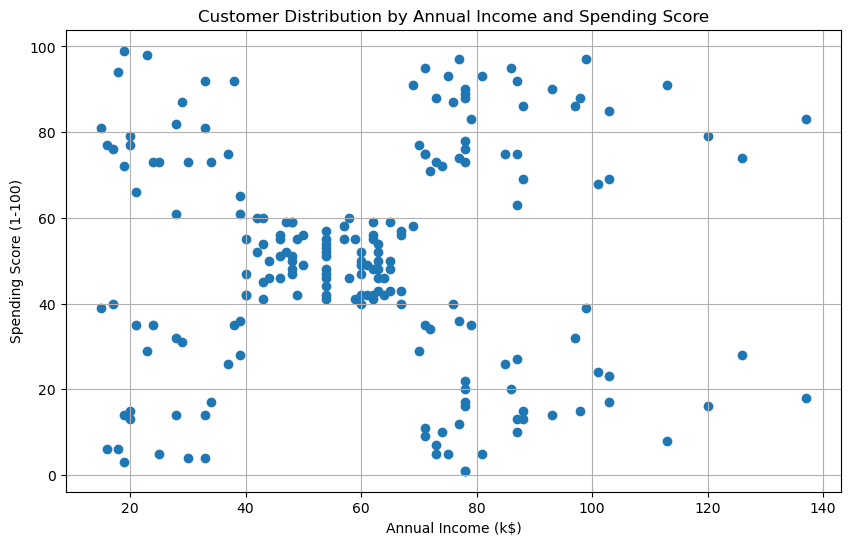

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
# Load the dataset
df = pd.read_csv("Mall_Customers.csv")
# Select features
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
# Create scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"]
)
# Add title and labels
plt.title("Customer Distribution by Annual Income and Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
# Display grid
plt.grid(True)
# Show plot
plt.show()

In [34]:
# Check missing values in selected features
print("Missing Values:")
print(X.isnull().sum())
# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())
# Check data types
print("\nData Types:")
print(X.dtypes)

Missing Values:
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows: 0

Data Types:
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


In [35]:
from sklearn.preprocessing import StandardScaler
# Create the scaler
scaler = StandardScaler()
# Scale the selected features
X_scaled = scaler.fit_transform(X)
# Convert scaled data into a DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)
# Display the first five scaled rows
print("Scaled Features:")
print(X_scaled.head())
# Check the scaled data shape
print("\nScaled Data Shape:", X_scaled.shape)

Scaled Features:
   Annual Income (k$)  Spending Score (1-100)
0           -1.738999               -0.434801
1           -1.738999                1.195704
2           -1.700830               -1.715913
3           -1.700830                1.040418
4           -1.662660               -0.395980

Scaled Data Shape: (200, 2)


In [36]:
from sklearn.cluster import KMeans
# Store inertia values for different cluster counts
inertia_values = []
# Test cluster counts from 1 to 10
k_values = range(1, 11)
for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia_values.append(model.inertia_)
# Display inertia values
for k, inertia in zip(k_values, inertia_values):
    print(f"Clusters: {k}, Inertia: {inertia:.2f}")

Clusters: 1, Inertia: 400.00
Clusters: 2, Inertia: 269.69
Clusters: 3, Inertia: 157.70
Clusters: 4, Inertia: 108.92
Clusters: 5, Inertia: 65.57
Clusters: 6, Inertia: 55.06
Clusters: 7, Inertia: 44.86
Clusters: 8, Inertia: 37.23
Clusters: 9, Inertia: 32.39
Clusters: 10, Inertia: 29.98


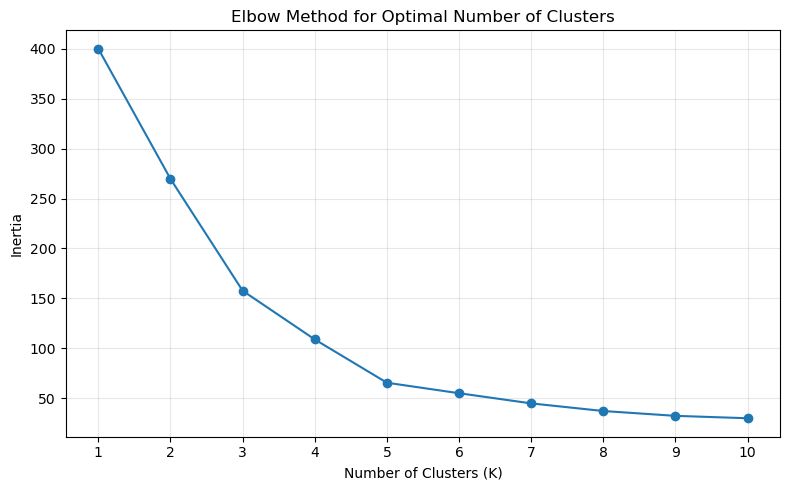

In [37]:
plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
# Enter the cluster count selected from the Elbow Method
optimal_k = 5
print("Selected Number of Clusters:", optimal_k)

Selected Number of Clusters: 5


In [39]:
# Create the K-Means model
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)
# Train the model and assign cluster labels
cluster_labels = kmeans.fit_predict(X_scaled)
print("K-Means Model Trained Successfully!")
print("Number of Clusters:", optimal_k)

K-Means Model Trained Successfully!
Number of Clusters: 5


In [40]:
# Add cluster labels to the original dataset
df["Cluster"] = cluster_labels
# Display customers with their assigned clusters
print(df.head(10))
# Count customers in each cluster
print("\nCustomers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   
5           6  Female   22                  17                      76   
6           7  Female   35                  18                       6   
7           8  Female   23                  18                      94   
8           9    Male   64                  19                       3   
9          10  Female   30                  19                      72   

   Cluster  
0        4  
1        2  
2        4  
3        2  
4        4  
5        2  
6        4  
7        2  
8        4  
9        2  

Customers in Each Cluster:
Cluster
0    8

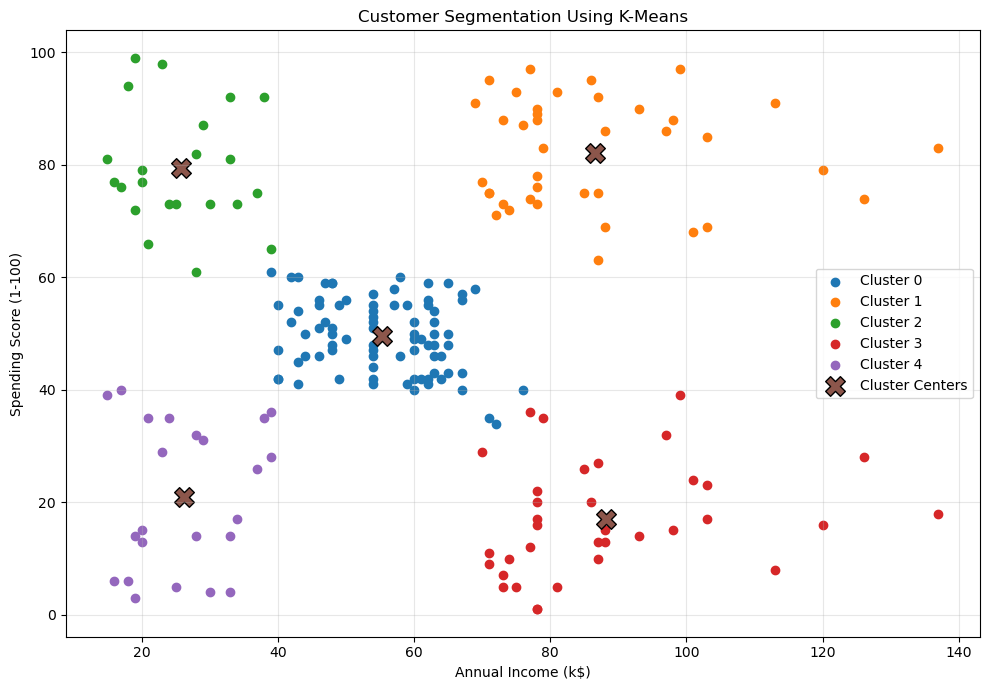

In [41]:
plt.figure(figsize=(10, 7))
# Plot customers belonging to each cluster
for cluster_id in sorted(df["Cluster"].unique()):

    cluster_data = df[df["Cluster"] == cluster_id]

    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster_id}"
    )

# Convert cluster centers back to original feature scales
centers_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

# Plot cluster centers
plt.scatter(
    centers_original[:, 0],
    centers_original[:, 1],
    marker="X",
    s=200,
    edgecolor="black",
    label="Cluster Centers"
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
# Calculate the characteristics of each customer cluster
cluster_summary = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print("CUSTOMER CLUSTER ANALYSIS")
print()
print(cluster_summary)

CUSTOMER CLUSTER ANALYSIS

         Customer_Count  Average_Age  Average_Annual_Income  \
Cluster                                                       
0                    81        42.72                  55.30   
1                    39        32.69                  86.54   
2                    22        25.27                  25.73   
3                    35        41.11                  88.20   
4                    23        45.22                  26.30   

         Average_Spending_Score  
Cluster                          
0                         49.52  
1                         82.13  
2                         79.36  
3                         17.11  
4                         20.91  


In [43]:
from sklearn.metrics import silhouette_score
# Evaluate the clustering model
score = silhouette_score(X_scaled, df["Cluster"])
print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.5547


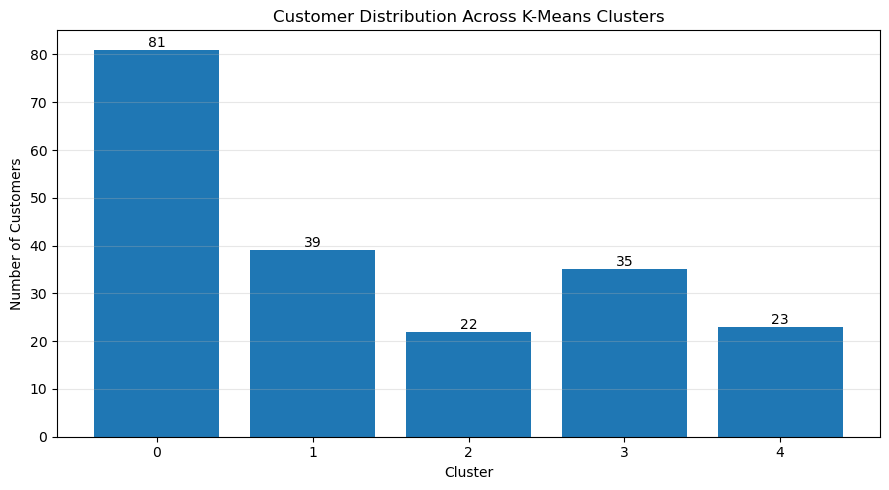

In [44]:
import matplotlib.pyplot as plt
# Count customers in each cluster
cluster_counts = df["Cluster"].value_counts().sort_index()
# Create bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)
# Add customer counts above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

# Add title and labels
plt.title("Customer Distribution Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
# Save the dataset with cluster labels
output_file = "Mall_Customers_Segmented.csv"

df.to_csv(output_file, index=False)

print("Dataset saved successfully!")
print("File name:", output_file)
print("Total customers:", len(df))
print("Total columns:", len(df.columns))

Dataset saved successfully!
File name: Mall_Customers_Segmented.csv
Total customers: 200
Total columns: 6


In [46]:
import os
import pandas as pd

file_name = "Mall_Customers_Segmented.csv"

if os.path.exists(file_name):
    saved_df = pd.read_csv(file_name)

    print("File verified successfully!")
    print("\nDataset Shape:", saved_df.shape)
    print("\nFirst 5 Rows:")
    print(saved_df.head())

    print("\nCluster Counts:")
    print(saved_df["Cluster"].value_counts().sort_index())

else:
    print("File not found. Please check your working directory.")

File verified successfully!

Dataset Shape: (200, 6)

First 5 Rows:
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Cluster  
0        4  
1        2  
2        4  
3        2  
4        4  

Cluster Counts:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [47]:
import os

print("Current Folder:", os.getcwd())

print("\nProject Files:")
print(os.listdir())

Current Folder: /Users/priyanshukumar/Documents/Internship/Bank Marketing Data Cleaning/Week 3 Customer Segmentation

Project Files:
['Mall_Customers.csv', 'Mall_Customers_Segmented.csv', 'Week3_Customer_Segmentation.ipynb', '.ipynb_checkpoints']


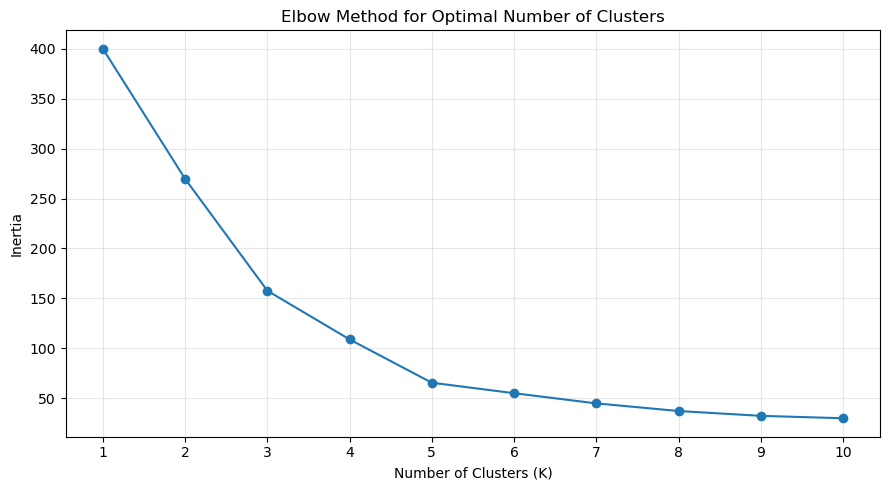

In [48]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
# Calculate inertia for different cluster counts
inertia_values = []
k_values = range(1, 11)
for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()